# Data Preprocessing: BreadBasket Dataset


### 1. Import Library


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')


### 2. Membaca Dataset


In [2]:
df = pd.read_csv('BreadBasket_DMS.csv')


### 3. Menampilkan 5 Data Teratas (Head)


In [3]:
df.head()


,Date,Time,Transaction,Item
0,2016-10-30,09:58:11,1,Bread
1,2016-10-30,10:05:34,2,Scandinavian
2,2016-10-30,10:05:34,2,Scandinavian
3,2016-10-30,10:07:57,3,Hot chocolate
4,2016-10-30,10:07:57,3,Jam


### 4. Menampilkan 5 Data Terbawah (Tail)


In [4]:
df.tail()


,Date,Time,Transaction,Item
21288,2017-04-09,14:32:58,9682,Coffee
21289,2017-04-09,14:32:58,9682,Tea
21290,2017-04-09,14:57:06,9683,Coffee
21291,2017-04-09,14:57:06,9683,Pastry
21292,2017-04-09,15:04:24,9684,Smoothies


### 5. Jumlah Baris (Record)


In [5]:
print("Jumlah Baris:", df.shape[0])


Jumlah Baris: 21293


### 6. Jumlah Kolom (Atribut)


In [6]:
print("Jumlah Kolom:", df.shape[1])


Jumlah Kolom: 4


### 7. Cek Tipe Data


In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21293 entries, 0 to 21292
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Date         21293 non-null  object
 1   Time         21293 non-null  object
 2   Transaction  21293 non-null  int64 
 3   Item         21293 non-null  object
dtypes: int64(1), object(3)
memory usage: 665.5+ KB


### 8. Ubah Nilai 'NONE' Menjadi NaN


In [8]:
df['Item'] = df['Item'].replace('NONE', np.nan)


### 9. Cek Missing Value per Kolom


In [9]:
df.isna().sum()


Date             0
Time             0
Transaction      0
Item           786
dtype: int64

### 10. Total Missing Value


In [10]:
print("Total Missing Value:", df.isna().sum().sum())


Total Missing Value: 786


### 11. Persentase Missing Value (%)


In [11]:
(df.isna().sum() / len(df) * 100).round(2)


Date           0.00
Time           0.00
Transaction    0.00
Item           3.69
dtype: float64

### 12. Visualisasi Heatmap Missing Value


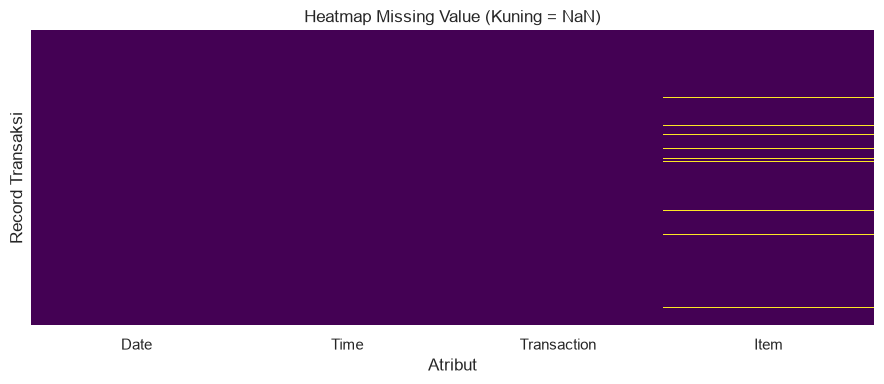

In [12]:
plt.figure(figsize=(9, 4))
sns.heatmap(df.isna(), cbar=False, cmap='viridis', yticklabels=False)
plt.title("Heatmap Missing Value (Kuning = NaN)")
plt.xlabel("Atribut")
plt.ylabel("Record Transaksi")
plt.tight_layout()
plt.show()


### 13. Cek Jumlah Duplikat


In [13]:
print("Jumlah Duplikat Penuh:", df.duplicated().sum())


Jumlah Duplikat Penuh: 1653


### 14. Cek Jumlah Transaksi Unik (ID)


In [14]:
print("Jumlah Transaksi Unik:", df['Transaction'].nunique())


Jumlah Transaksi Unik: 9531


### 15. Hitung Jumlah Barang per Transaksi


In [15]:
item_per_transaksi = df.dropna(subset=['Item']).groupby('Transaction')['Item'].count()
item_per_transaksi.head()


Transaction
1    1
2    2
3    3
4    1
5    3
Name: Item, dtype: int64

### 16. Statistik Ukuran Keranjang Belanja


In [16]:
item_per_transaksi.describe()


count    9465.000000
mean        2.166614
std         1.301303
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max        11.000000
Name: Item, dtype: float64

### 17. Visualisasi Boxplot Deteksi Outlier


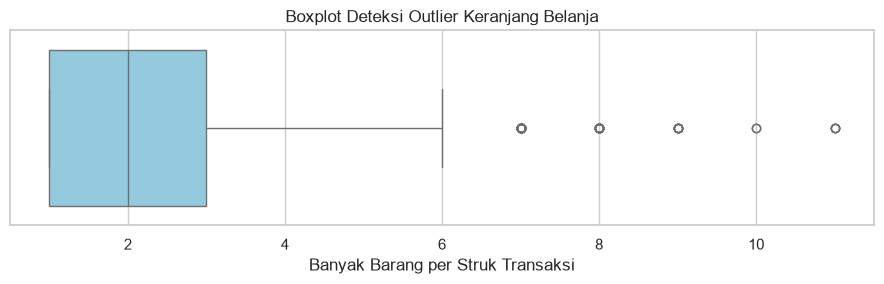

In [17]:
plt.figure(figsize=(9, 3))
sns.boxplot(x=item_per_transaksi, color='skyblue')
plt.title("Boxplot Deteksi Outlier Keranjang Belanja")
plt.xlabel("Banyak Barang per Struk Transaksi")
plt.tight_layout()
plt.show()


### 18. Perhitungan Kuartil dan IQR


In [18]:
Q1 = item_per_transaksi.quantile(0.25)
Q3 = item_per_transaksi.quantile(0.75)
IQR = Q3 - Q1

print("Kuartil 1 (Q1) :", Q1)
print("Kuartil 3 (Q3) :", Q3)
print("IQR            :", IQR)


Kuartil 1 (Q1) : 1.0
Kuartil 3 (Q3) : 3.0
IQR            : 2.0


### 19. Batas Atas Outlier


In [19]:
batas_atas = Q3 + 1.5 * IQR
print("Batas Atas Outlier:", batas_atas, "barang")


Batas Atas Outlier: 6.0 barang


### 20. Jumlah Transaksi yang Terdeteksi Outlier


In [20]:
outliers = item_per_transaksi[item_per_transaksi > batas_atas]
print("Jumlah Transaksi Outlier:", len(outliers))


Jumlah Transaksi Outlier: 72


### 21. 10 Transaksi dengan Belanja Terbanyak (Outlier)


In [21]:
outliers.sort_values(ascending=False).head(10)


Transaction
6412    11
6474    11
6716    11
6279    11
6045    10
9447    10
3799     9
3673     9
6519     9
8835     9
Name: Item, dtype: int64